# Proyecto Completo de Machine Learning
Realizado por: Alexander Sanchez Jara

## Predicción de Necesidad de Tratamiento de Salud Mental en el Sector Tecnológico

**Apartados del proyecto abordados en este cuaderno:**
1. Obtención de datos
2. Descripción de los datos
3. Exploración y visualización de los datos
4. Exposición del objetivo
5. Preparación de los datos para los algoritmos de Machine Learning
6. Entrenamiento de los modelos y comprobación del rendimiento
7. Conclusiones

---
### 1. Obtención de datos

* **Fuente de los datos:** Dataset *"Mental Health in Tech Survey"*, recopilado por **Open Sourcing Mental Illness (OSMI)** y publicado en **Kaggle**.
* **Medio de obtención:** Los datos se han obtenido mediante **encuestas estructuradas** respondidas de forma anónima por profesionales y trabajadores del sector tecnológico, recogiendo información demográfica, antecedentes personales y percepción sobre las políticas de salud mental en sus empresas.
* **Estructura de carga:** Se cargan los datos en un `DataFrame` de `pandas` desde Google Drive para facilitar su limpieza, análisis exploratorio, transformación y posterior entrenamiento de modelos supervisados.

In [ ]:
from google.colab import drive

# Montar Google Drive en el entorno de Google Colab
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

# Configuración estética global de las gráficas
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams['figure.dpi'] = 100

# Carga del dataset desde Google Drive con codificación 'latin1' para evitar errores de decodificación
ruta_dataset = '/content/drive/MyDrive/datasets/mental_health_survey.csv'

try:
    df = pd.read_csv(ruta_dataset, encoding='latin1')
    print(f"Datos cargados correctamente desde Google Drive. Dimensiones: {df.shape[0]} filas x {df.shape[1]} columnas.")
except FileNotFoundError:
    print(f"No se encontró el archivo en la ruta especificada: {ruta_dataset}")
    print("Verifica que la ruta de carpetas y el nombre del archivo en tu Drive sean exactos.")
except Exception as e:
    print("Ocurrió un error al cargar el archivo:", e)

Datos cargados correctamente desde Google Drive. Dimensiones: 1259 filas x 27 columnas.


---
### 2. Descripción de los datos

El conjunto de datos consta de **1.259 registros** y **27 atributos** que describen el perfil demográfico, laboral y de percepción sobre salud mental de cada encuestado:

| N.º | Atributo | Tipo | Descripción |
| :--- | :--- | :--- | :--- |
| 1 | `Timestamp` | Texto / Fecha | Marca temporal con la fecha y hora en que se envió la encuesta. |
| 2 | `Age` | Numérico (`int`) | Edad del encuestado en años. |
| 3 | `Gender` | Categórico (texto libre) | Género con el que se identifica la persona encuestada. |
| 4 | `Country` | Categórico | País de residencia del encuestado. |
| 5 | `state` | Categórico | Estado o territorio de residencia (aplicable principalmente a EE. UU.). |
| 6 | `self_employed` | Categórico (`Yes`/`No`) | Indica si la persona trabaja por cuenta propia (autónomo/freelance). |
| 7 | `family_history` | Categórico (`Yes`/`No`) | Indica si existen antecedentes familiares de enfermedades mentales. |
| 8 | `treatment` | **Categórico (`Yes`/`No`)** | **Variable objetivo (Target):** indica si el encuestado ha buscado tratamiento profesional para una condición de salud mental. |
| 9 | `work_interfere` | Categórico ordinal | Frecuencia con la que una condición de salud mental interfiere en su desempeño laboral (`Never`, `Rarely`, `Sometimes`, `Often`, `Don't know`). |
| 10 | `no_employees` | Categórico ordinal | Tamaño de la empresa según el número de empleados (`1-5`, `6-25`, `26-100`, `100-500`, `500-1000`, `More than 1000`). |
| 11 | `remote_work` | Categórico (`Yes`/`No`) | Indica si trabaja de forma remota al menos el 50 % del tiempo. |
| 12 | `tech_company` | Categórico (`Yes`/`No`) | Indica si la empresa pertenece principalmente al sector tecnológico. |
| 13 | `benefits` | Categórico | Indica si la empresa ofrece beneficios o cobertura de salud mental (`Yes`, `No`, `Don't know`). |
| 14 | `care_options` | Categórico | Indica si el empleado conoce las opciones de atención en salud mental ofrecidas por su empresa (`Yes`, `No`, `Not sure`). |
| 15 | `wellness_program` | Categórico | Indica si la empresa incluye la salud mental en programas de bienestar laboral (`Yes`, `No`, `Don't know`). |
| 16 | `seek_help` | Categórico | Indica si la empresa facilita recursos para informarse y buscar ayuda (`Yes`, `No`, `Don't know`). |
| 17 | `anonymity` | Categórico | Indica si se garantiza el anonimato al hacer uso de recursos de salud mental (`Yes`, `No`, `Don't know`). |
| 18 | `leave` | Categórico ordinal | Facilidad percibida para solicitar una baja médica por motivos de salud mental (`Very easy`, `Somewhat easy`, `Don't know`, `Somewhat difficult`, `Very difficult`). |
| 19 | `mental_health_consequence` | Categórico | Percepción sobre si hablar de salud mental con el empleador tendría consecuencias negativas (`Yes`, `No`, `Maybe`). |
| 20 | `phys_health_consequence` | Categórico | Percepción sobre si hablar de salud física con el empleador tendría consecuencias negativas (`Yes`, `No`, `Maybe`). |
| 21 | `coworkers` | Categórico | Disposición a hablar sobre problemas de salud mental con compañeros de trabajo (`Yes`, `No`, `Some of them`). |
| 22 | `supervisor` | Categórico | Disposición a hablar sobre problemas de salud mental con su supervisor directo (`Yes`, `No`, `Some of them`). |
| 23 | `mental_health_interview` | Categórico | Disposición a mencionar un problema de salud mental en una entrevista de trabajo (`Yes`, `No`, `Maybe`). |
| 24 | `phys_health_interview` | Categórico | Disposición a mencionar un problema de salud física en una entrevista de trabajo (`Yes`, `No`, `Maybe`). |
| 25 | `mental_vs_physical` | Categórico | Percepción sobre si la empresa da la misma importancia a la salud mental que a la física (`Yes`, `No`, `Don't know`). |
| 26 | `obs_consequence` | Categórico (`Yes`/`No`) | Indica si ha observado consecuencias negativas hacia compañeros con trastornos de salud mental en su trabajo. |
| 27 | `comments` | Texto libre | Comentarios adicionales abiertos proporcionados por el encuestado. |

A continuación inspeccionamos las primeras filas, los tipos de datos y las estadísticas descriptivas iniciales:

In [ ]:
# Vista previa de los datos
print("--- Primeras 5 filas del dataset ---")
display(df.head())

# Información de tipos de datos y valores no nulos
print("\n--- Estructura y tipos de datos del DataFrame ---")
df.info()

# Resumen estadístico de variables numéricas
print("\n--- Descripción estadística inicial ---")
display(df.describe())

--- Primeras 5 filas del dataset ---


,Timestamp,Age,Gender,Country,state,self_employed,family_history,treatment,work_interfere,no_employees,...,leave,mental_health_consequence,phys_health_consequence,coworkers,supervisor,mental_health_interview,phys_health_interview,mental_vs_physical,obs_consequence,comments
0,2014-08-27 11:29:31,37,Female,United States,IL,NaN,No,Yes,Often,6-25,...,Somewhat easy,No,No,Some of them,Yes,No,Maybe,Yes,No,NaN
1,2014-08-27 11:29:37,44,M,United States,IN,NaN,No,No,Rarely,More than 1000,...,Don't know,Maybe,No,No,No,No,No,Don't know,No,NaN
2,2014-08-27 11:29:44,32,Male,Canada,NaN,NaN,No,No,Rarely,6-25,...,Somewhat difficult,No,No,Yes,Yes,Yes,Yes,No,No,NaN
3,2014-08-27 11:29:46,31,Male,United Kingdom,NaN,NaN,Yes,Yes,Often,26-100,...,Somewhat difficult,Yes,Yes,Some of them,No,Maybe,Maybe,No,Yes,NaN
4,2014-08-27 11:30:22,31,Male,United States,TX,NaN,No,No,Never,100-500,...,Don't know,No,No,Some of them,Yes,Yes,Yes,Don't know,No,NaN



--- Estructura y tipos de datos del DataFrame ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1259 entries, 0 to 1258
Data columns (total 27 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   Timestamp                  1259 non-null   object
 1   Age                        1259 non-null   int64 
 2   Gender                     1259 non-null   object
 3   Country                    1259 non-null   object
 4   state                      744 non-null    object
 5   self_employed              1241 non-null   object
 6   family_history             1259 non-null   object
 7   treatment                  1259 non-null   object
 8   work_interfere             995 non-null    object
 9   no_employees               1259 non-null   object
 10  remote_work                1259 non-null   object
 11  tech_company               1259 non-null   object
 12  benefits                   1259 non-null   object
 13  care_options

,Age
count,1.259000e+03
mean,7.942815e+07
std,2.818299e+09
min,-1.726000e+03
25%,2.700000e+01
50%,3.100000e+01
75%,3.600000e+01
max,1.000000e+11


---
### 3. Exploración y visualización de los datos (EDA)

En esta fase analizamos la calidad de los datos, detectamos valores atípicos o imposibles (como edades negativas o superiores a 100 años), revisamos valores nulos y representamos gráficas de **distinta tipología** (barras, histograma con densidad, diagrama de cajas y mapa de calor de correlaciones) para comprender las relaciones clave del dataset.

In [ ]:
# 3.1 Detección y filtrado de valores atípicos en la edad (rango laboral válido: 18 a 75 años)
df_clean = df[(df['Age'] >= 18) & (df['Age'] <= 75)].copy()
print(f"Filas tras filtrar edades anómalas: {df_clean.shape[0]} (se eliminaron {df.shape[0] - df_clean.shape[0]} registros con edades imposibles).")

# Comprobación de valores nulos por columna
print("\n--- Valores nulos por columna en el dataset limpio ---")
nulos = df_clean.isnull().sum()
print(nulos[nulos > 0])

# Estadística descriptiva de la edad tras la depuración
print("\n--- Estadística descriptiva de Age (limpia) ---")
display(df_clean[['Age']].describe().T)

# Inspección de valores únicos en Gender (muestra por qué requiere estandarización)
print(f"\nNúmero de categorías distintas en 'Gender' antes de limpiar: {df_clean['Gender'].nunique()}")
print("Ejemplos de valores en 'Gender':", df_clean['Gender'].unique()[:15])

Filas tras filtrar edades anómalas: 1251 (se eliminaron 8 registros con edades imposibles).

--- Valores nulos por columna en el dataset limpio ---
state              513
self_employed       18
work_interfere     262
comments          1090
dtype: int64

--- Estadística descriptiva de Age (limpia) ---


,count,mean,std,min,25%,50%,75%,max
Age,1251.0,32.076739,7.288272,18.0,27.0,31.0,36.0,72.0



Número de categorías distintas en 'Gender' antes de limpiar: 46
Ejemplos de valores en 'Gender': ['Female' 'M' 'Male' 'male' 'female' 'm' 'Male-ish' 'maile' 'Trans-female'
 'Cis Female' 'F' 'something kinda male?' 'Cis Male' 'Woman' 'f']


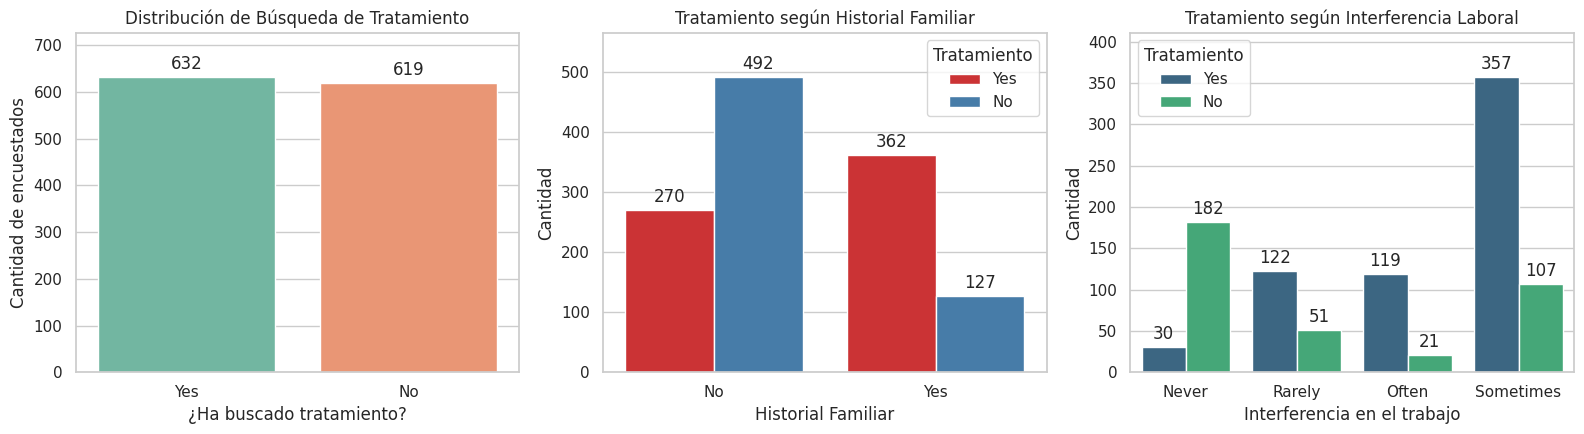

In [ ]:
# 3.2 Gráficos de Barras (Countplots): Distribución del Target y relación con variables clave
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Gráfico 1: Distribución de la variable objetivo (treatment)
ax1 = sns.countplot(x='treatment', data=df_clean, hue='treatment', palette='Set2', legend=False, ax=axes[0])
for container in ax1.containers:
    ax1.bar_label(container, fmt='%d', padding=3)
ax1.margins(y=0.15)
ax1.set_title('Distribución de Búsqueda de Tratamiento')
ax1.set_xlabel('¿Ha buscado tratamiento?')
ax1.set_ylabel('Cantidad de encuestados')

# Gráfico 2: Tratamiento según Historial Familiar
ax2 = sns.countplot(x='family_history', hue='treatment', data=df_clean, palette='Set1', ax=axes[1])
for container in ax2.containers:
    ax2.bar_label(container, fmt='%d', padding=3)
ax2.margins(y=0.15)
ax2.set_title('Tratamiento según Historial Familiar')
ax2.set_xlabel('Historial Familiar')
ax2.set_ylabel('Cantidad')
ax2.legend(title='Tratamiento')

# Gráfico 3: Tratamiento según Interferencia en el Trabajo
orden_interfere = ['Never', 'Rarely', 'Often', 'Sometimes']
ax3 = sns.countplot(x='work_interfere', hue='treatment', data=df_clean, order=orden_interfere, palette='viridis', ax=axes[2])
for container in ax3.containers:
    ax3.bar_label(container, fmt='%d', padding=3)
ax3.margins(y=0.15)
ax3.set_title('Tratamiento según Interferencia Laboral')
ax3.set_xlabel('Interferencia en el trabajo')
ax3.set_ylabel('Cantidad')
ax3.legend(title='Tratamiento')

plt.tight_layout()
plt.show()

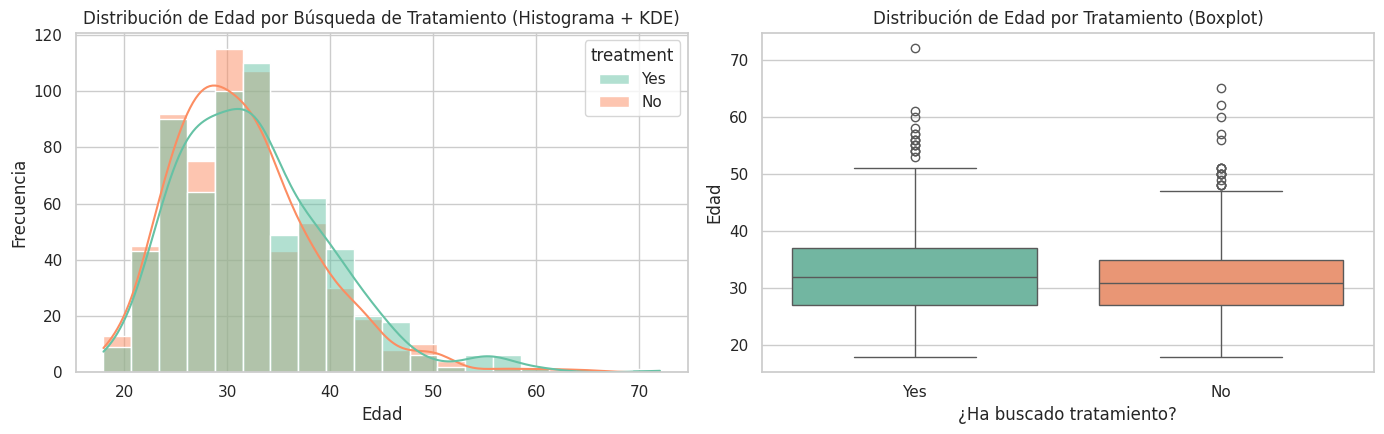

In [ ]:
# 3.3 Histograma + Curva KDE y Diagrama de Cajas (Boxplot) para la distribución de Edad
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Histograma con estimación de densidad (KDE)
sns.histplot(data=df_clean, x='Age', hue='treatment', kde=True, bins=20, palette='Set2', ax=axes[0])
axes[0].set_title('Distribución de Edad por Búsqueda de Tratamiento (Histograma + KDE)')
axes[0].set_xlabel('Edad')
axes[0].set_ylabel('Frecuencia')

# Diagrama de cajas (Boxplot)
sns.boxplot(data=df_clean, x='treatment', y='Age', hue='treatment', palette='Set2', legend=False, ax=axes[1])
axes[1].set_title('Distribución de Edad por Tratamiento (Boxplot)')
axes[1].set_xlabel('¿Ha buscado tratamiento?')
axes[1].set_ylabel('Edad')

plt.tight_layout()
plt.show()

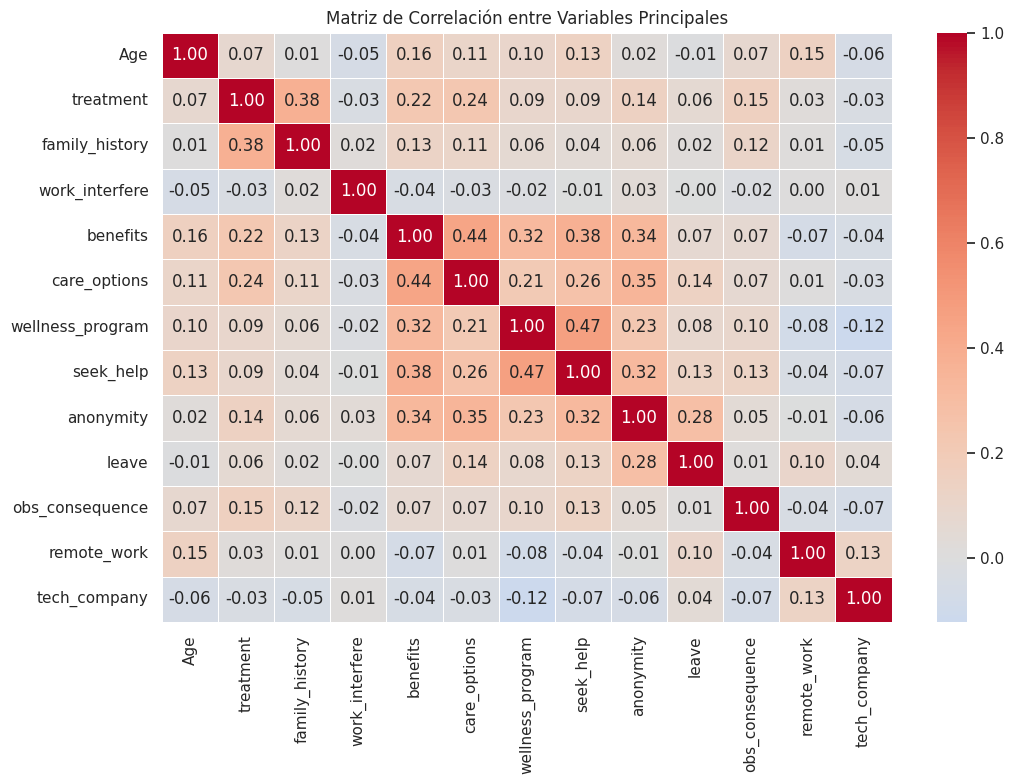

In [ ]:
# 3.4 Estudio de Correlaciones (Mapa de Calor / Heatmap)
# Codificamos temporalmente las variables categóricas relevantes para analizar correlaciones
df_corr = df_clean[['Age', 'treatment', 'family_history', 'work_interfere', 'benefits',
                    'care_options', 'wellness_program', 'seek_help', 'anonymity',
                    'leave', 'obs_consequence', 'remote_work', 'tech_company']].copy()

for col in df_corr.columns:
    if df_corr[col].dtype == 'object':
        df_corr[col] = df_corr[col].fillna('Unknown').astype('category').cat.codes

plt.figure(figsize=(11, 8))
matriz_corr = df_corr.corr()
sns.heatmap(matriz_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Matriz de Correlación entre Variables Principales')
plt.tight_layout()
plt.show()

---
### 4. Exposición del objetivo

A partir del análisis exploratorio anterior, se observa que la variable `treatment` está muy equilibrada (~50,5 % `Yes` y ~49,5 % `No`) y guarda una fuerte relación con factores como la interferencia laboral (`work_interfere`), los antecedentes familiares (`family_history`), el conocimiento de las opciones de atención (`care_options`) y los beneficios empresariales (`benefits`).

* **Tipo de problema:** Aprendizaje supervisado de **Clasificación Binaria**.
* **Target (variable objetivo a predecir):** `treatment` (`1` = Sí ha buscado tratamiento de salud mental, `0` = No ha buscado tratamiento).
* **Finalidad práctica:** Predecir la probabilidad de que un empleado del sector tecnológico requiera o busque atención en salud mental en función de sus características personales y del entorno organizacional, permitiendo diseñar políticas preventivas de apoyo laboral.

---
### 5. Preparación de los datos para los algoritmos de Machine Learning

En esta etapa dejamos el conjunto de datos completamente preparado para entrenar modelos supervisados siguiendo estos pasos:
1. **Tratamiento de valores nulos:** Imputamos los valores ausentes en `self_employed` (`'No'`) y `work_interfere` (`"Don't know"`).
2. **Estandarización de `Gender` en 3 categorías (`Male`, `Female`, `Other`):** Unificamos las 49 variantes de texto libre introducidas en la encuesta original (errores tipográficos como *Mail*, *Femake*, abreviaturas como *M*, *F*, o identidades no binarias/trans) en tres categorías limpias y consistentes: `Male`, `Female` y `Other`.
3. **Selección y codificación de variables:** Eliminamos columnas identificadoras o con exceso de nulos no estructurales (`Timestamp`, `comments`, `state`, `Country`), codificamos el target `treatment` con `LabelEncoder` y aplicamos *One-Hot Encoding* (`pd.get_dummies`) a las características categóricas.
4. **División Train/Test (80 % / 20 %) y escalado:** Separamos de forma estratificada y estandarizamos las características numéricas con `StandardScaler` ajustado exclusivamente sobre el conjunto de entrenamiento para evitar fuga de datos (*data leakage*).

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

df_prep = df_clean.copy()

# 5.1 Tratamiento de valores nulos
df_prep['self_employed'] = df_prep['self_employed'].fillna('No')
df_prep['work_interfere'] = df_prep['work_interfere'].fillna("Don't know")

# 5.2 Estandarización de la columna 'Gender' en Male, Female y Other
def estandarizar_genero(valor):
    g = str(valor).strip().lower()
    variantes_male = {
        'male', 'm', 'man', 'cis male', 'cis man', 'male (cis)',
        'mail', 'maile', 'mal', 'msle', 'malr', 'make', 'male-ish'
    }
    variantes_female = {
        'female', 'f', 'woman', 'cis female', 'cis-female/femme',
        'female (cis)', 'femake', 'femail'
    }
    if g in variantes_male:
        return 'Male'
    elif g in variantes_female:
        return 'Female'
    else:
        return 'Other'

df_prep['Gender'] = df_prep['Gender'].apply(estandarizar_genero)

print("--- Distribución de 'Gender' tras la estandarización ---")
print(df_prep['Gender'].value_counts())

# 5.3 Separación de características (X) y variable objetivo (y)
X = df_prep.drop(['treatment', 'Timestamp', 'comments', 'state', 'Country'], axis=1, errors='ignore')
y_raw = df_prep['treatment']

# Codificación del target (No -> 0, Yes -> 1)
le = LabelEncoder()
y = le.fit_transform(y_raw)

# Codificación One-Hot de variables predictoras categóricas
X_encoded = pd.get_dummies(X, drop_first=True)

# 5.4 División estratificada en conjuntos de entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

# 5.5 Escalado estándar (fit solo en train para evitar data leakage)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nDatos preparados correctamente para el entrenamiento:")
print(f"Dimensiones de X_train_scaled: {X_train_scaled.shape}")
print(f"Dimensiones de X_test_scaled:  {X_test_scaled.shape}")

--- Distribución de 'Gender' tras la estandarización ---
Gender
Male      986
Female    247
Other      18
Name: count, dtype: int64

Datos preparados correctamente para el entrenamiento:
Dimensiones de X_train_scaled: (1000, 45)
Dimensiones de X_test_scaled:  (251, 45)


---
### 6. Entrenamiento de los modelos y comprobación del rendimiento

Para resolver el problema de clasificación binaria evaluaremos distintos algoritmos de Machine Learning utilizando métricas complementarias: **Accuracy** (exactitud global), **Precision**, **Recall** (sensibilidad), **F1-Score**, **ROC-AUC** y la **Matriz de Confusión**.

#### 6.1 Modelo Base: Random Forest Classifier
Entrenamos en primer lugar un clasificador `RandomForestClassifier` y analizamos su informe de clasificación y matriz de confusión sobre el conjunto de prueba.

Accuracy: 0.8327
ROC-AUC:  0.8901

Reporte de Clasificación:
               precision    recall  f1-score   support

      No (0)       0.85      0.81      0.83       124
     Yes (1)       0.82      0.86      0.84       127

    accuracy                           0.83       251
   macro avg       0.83      0.83      0.83       251
weighted avg       0.83      0.83      0.83       251



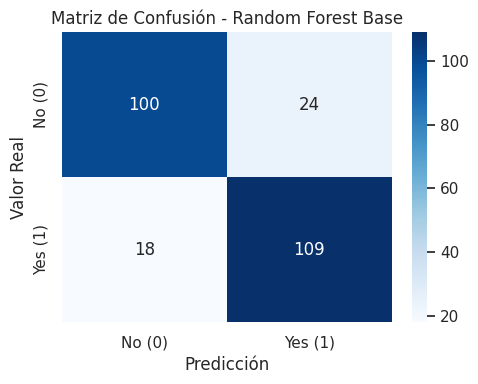

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix, RocCurveDisplay
)

# Instanciar y entrenar el modelo base Random Forest
model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    min_samples_split=2,
    criterion='entropy',
    random_state=42
)
model.fit(X_train_scaled, y_train)

# Predicciones en test
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

# Evaluación de rendimiento
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"ROC-AUC:  {roc_auc_score(y_test, y_prob):.4f}")
print("\nReporte de Clasificación:\n", classification_report(y_test, y_pred, target_names=['No (0)', 'Yes (1)']))

# Matriz de confusión
plt.figure(figsize=(5, 4))
sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True, fmt='d', cmap='Blues',
    xticklabels=['No (0)', 'Yes (1)'],
    yticklabels=['No (0)', 'Yes (1)']
)
plt.title('Matriz de Confusión - Random Forest Base')
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.tight_layout()
plt.show()

#### 6.2 Comparativa de Múltiples Algoritmos de Clasificación
Comparamos el rendimiento de **cuatro modelos distintos** sobre el mismo conjunto de entrenamiento y prueba:
* **Regresión Logística (`LogisticRegression`)**
* **Máquinas de Vectores de Soporte (`SVC`)**
* **Gradient Boosting (`GradientBoostingClassifier`)**
* **Random Forest (`RandomForestClassifier`)**

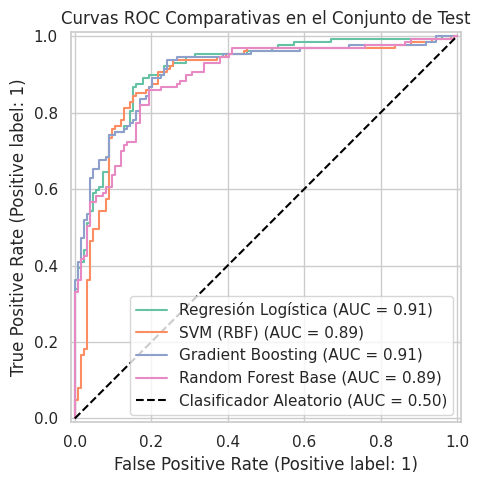

=== TABLA COMPARATIVA DE MODELOS ===


,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Regresión Logística,0.8486,0.8248,0.8898,0.8561,0.9129
1,SVM (RBF),0.8367,0.7905,0.9213,0.8509,0.8908
2,Gradient Boosting,0.8367,0.8162,0.8740,0.8441,0.9074
3,Random Forest Base,0.8327,0.8195,0.8583,0.8385,0.8901


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier

modelos = {
    'Regresión Logística': LogisticRegression(max_iter=1000, random_state=42),
    'SVM (RBF)': SVC(probability=True, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'Random Forest Base': RandomForestClassifier(
        n_estimators=200, max_depth=20, min_samples_split=2, criterion='entropy', random_state=42
    )
}

resultados_modelos = []

fig, ax = plt.subplots(figsize=(7, 5))

for nombre, clf in modelos.items():
    clf.fit(X_train_scaled, y_train)
    pred = clf.predict(X_test_scaled)
    prob = clf.predict_proba(X_test_scaled)[:, 1]

    resultados_modelos.append({
        'Modelo': nombre,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1-Score': f1_score(y_test, pred),
        'ROC-AUC': roc_auc_score(y_test, prob)
    })

    RocCurveDisplay.from_predictions(y_test, prob, name=nombre, ax=ax)

ax.plot([0, 1], [0, 1], 'k--', label='Clasificador Aleatorio (AUC = 0.50)')
ax.set_title('Curvas ROC Comparativas en el Conjunto de Test')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

df_resultados_modelos = pd.DataFrame(resultados_modelos).sort_values(by='Accuracy', ascending=False)
print("=== TABLA COMPARATIVA DE MODELOS ===")
display(df_resultados_modelos.round(4))

#### 6.3 Ajuste de Hiperparámetros (`GridSearchCV`)
Para optimizar el modelo `RandomForestClassifier`, realizamos una búsqueda sistemática de hiperparámetros mediante validación cruzada de 5 pliegues (`cv=5`), evaluando combinaciones de `n_estimators`, `max_depth`, `min_samples_split` y `criterion`.

Iniciando la búsqueda de los mejores hiperparámetros...
Fitting 5 folds for each of 72 candidates, totalling 360 fits

¡Búsqueda completada!
Mejores Hiperparámetros encontrados: {'criterion': 'entropy', 'max_depth': 10, 'min_samples_split': 10, 'n_estimators': 100}
Mejor Accuracy en Validación Cruzada (CV=5): 0.8210
Accuracy del Modelo Optimizado en Test:      0.8287
ROC-AUC del Modelo Optimizado en Test:       0.8959


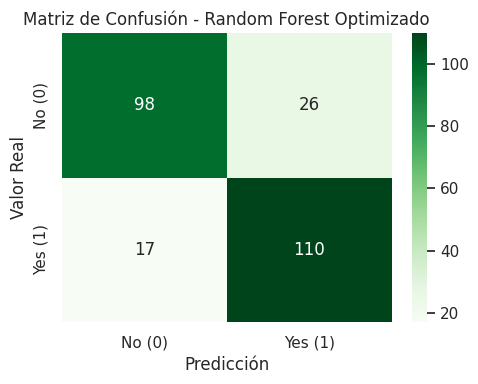

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'criterion': ['gini', 'entropy']
}

rf_base = RandomForestClassifier(random_state=42)

grid_search = GridSearchCV(
    estimator=rf_base,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

print("Iniciando la búsqueda de los mejores hiperparámetros...")
grid_search.fit(X_train_scaled, y_train)

best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(X_test_scaled)
y_prob_best = best_model.predict_proba(X_test_scaled)[:, 1]

print("\n¡Búsqueda completada!")
print("Mejores Hiperparámetros encontrados:", grid_search.best_params_)
print(f"Mejor Accuracy en Validación Cruzada (CV=5): {grid_search.best_score_:.4f}")
print(f"Accuracy del Modelo Optimizado en Test:      {accuracy_score(y_test, y_pred_best):.4f}")
print(f"ROC-AUC del Modelo Optimizado en Test:       {roc_auc_score(y_test, y_prob_best):.4f}")

# Matriz de confusión del modelo optimizado
plt.figure(figsize=(5, 4))
sns.heatmap(
    confusion_matrix(y_test, y_pred_best),
    annot=True, fmt='d', cmap='Greens',
    xticklabels=['No (0)', 'Yes (1)'],
    yticklabels=['No (0)', 'Yes (1)']
)
plt.title('Matriz de Confusión - Random Forest Optimizado')
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.tight_layout()
plt.show()

#### 6.4 Experimento: ¿Realmente importa el escalado en un Random Forest?
Los modelos basados en árboles de decisión realizan particiones por umbrales sobre cada característica de forma independiente, por lo que teóricamente son invariantes a transformaciones monótonas de escala. Lo comprobamos empíricamente entrenando el mismo `RandomForestClassifier` con los datos sin escalar (`X_train`, `X_test`) frente a los datos escalados (`X_train_scaled`, `X_test_scaled`).

In [ ]:
# Modelo entrenado con datos SIN escalar
modelo_sin_escalar = RandomForestClassifier(**grid_search.best_params_, random_state=42)
modelo_sin_escalar.fit(X_train, y_train)
accuracy_sin_escalar = accuracy_score(y_test, modelo_sin_escalar.predict(X_test))

# Modelo entrenado con datos CON escalar
modelo_con_escalar = RandomForestClassifier(**grid_search.best_params_, random_state=42)
modelo_con_escalar.fit(X_train_scaled, y_train)
accuracy_con_escalar = accuracy_score(y_test, modelo_con_escalar.predict(X_test_scaled))

print("=== COMPARACIÓN DE IMPACTO DEL ESCALADO ===")
print(f"Accuracy CON datos escalados: {accuracy_con_escalar:.5f}")
print(f"Accuracy SIN datos escalados: {accuracy_sin_escalar:.5f}")
print(f"Diferencia absoluta:          {abs(accuracy_con_escalar - accuracy_sin_escalar):.5f}")

=== COMPARACIÓN DE IMPACTO DEL ESCALADO ===
Accuracy CON datos escalados: 0.82869
Accuracy SIN datos escalados: 0.82869
Diferencia absoluta:          0.00000


#### 6.5 Importancia de las Variables (Feature Importance)
Extraemos el atributo `feature_importances_` del modelo `RandomForestClassifier` optimizado para identificar qué factores tienen mayor peso predictivo en la decisión de buscar tratamiento.

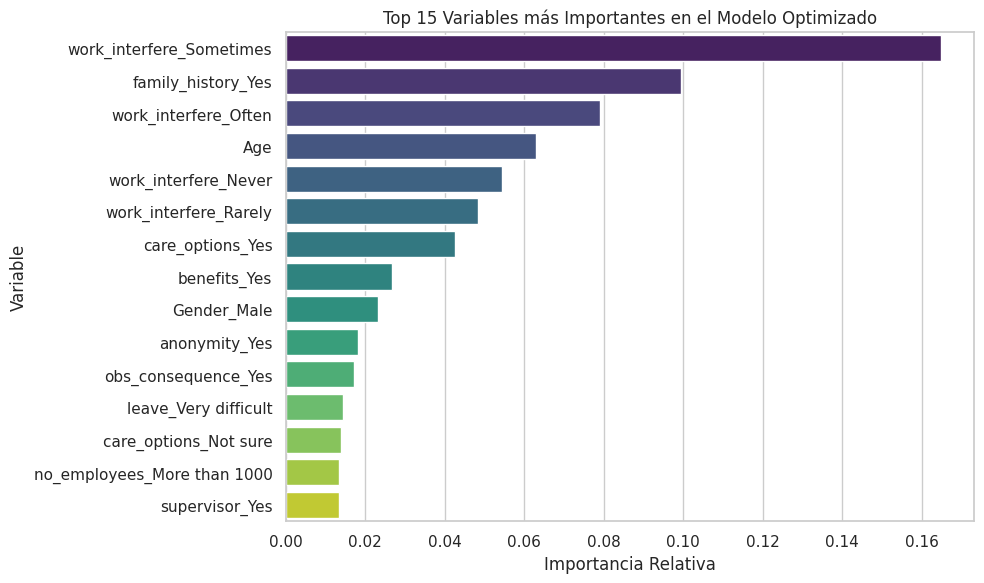

--- Ranking de importancia de todas las variables ---


,Variable,Importancia
0,work_interfere_Sometimes,0.164896
1,family_history_Yes,0.099566
2,work_interfere_Often,0.079090
3,Age,0.062963
4,work_interfere_Never,0.054525
5,work_interfere_Rarely,0.048393
6,care_options_Yes,0.042611
7,benefits_Yes,0.026717
8,Gender_Male,0.023171
9,anonymity_Yes,0.018169


In [ ]:
# Obtener la importancia de las variables desde el modelo optimizado
importancias = best_model.feature_importances_
nombres_variables = X_encoded.columns

df_importancia = pd.DataFrame({
    'Variable': nombres_variables,
    'Importancia': importancias
}).sort_values(by='Importancia', ascending=False).reset_index(drop=True)

# Visualizar únicamente el Top 15 de variables más importantes
top_15 = df_importancia.head(15)

plt.figure(figsize=(10, 6))
sns.barplot(
    x='Importancia',
    y='Variable',
    data=top_15,
    hue='Variable',
    palette='viridis',
    legend=False
)
plt.title('Top 15 Variables más Importantes en el Modelo Optimizado')
plt.xlabel('Importancia Relativa')
plt.ylabel('Variable')
plt.tight_layout()
plt.show()

print("--- Ranking de importancia de todas las variables ---")
display(df_importancia)

#### 6.6 Experimento de Selección de Características (Feature Selection) por Umbral de Importancia
Evaluamos si es posible reducir la dimensionalidad del modelo eliminando variables poco informativas sin perder capacidad predictiva, probando dos umbrales de importancia relativa:
1. Importancia mayor a **0.01**
2. Importancia mayor a **0.02**

In [ ]:
umbrales = [0.01, 0.02]
columnas_originales = X_encoded.columns
resultados_experimento = []

# Caso base (todas las variables)
resultados_experimento.append({
    'Umbral': 'Ninguno (Base)',
    'Num_Variables': len(columnas_originales),
    'Accuracy_Test': accuracy_score(y_test, best_model.predict(X_test_scaled))
})

for umbral in umbrales:
    variables_filtradas = df_importancia[df_importancia['Importancia'] > umbral]['Variable'].tolist()
    num_vars = len(variables_filtradas)
    indices_columnas = [X_encoded.columns.get_loc(col) for col in variables_filtradas]

    X_train_filtrado = X_train_scaled[:, indices_columnas]
    X_test_filtrado = X_test_scaled[:, indices_columnas]

    modelo_filtrado = RandomForestClassifier(**grid_search.best_params_, random_state=42)
    modelo_filtrado.fit(X_train_filtrado, y_train)

    y_pred_fil = modelo_filtrado.predict(X_test_filtrado)
    acc_fil = accuracy_score(y_test, y_pred_fil)

    resultados_experimento.append({
        'Umbral': f'> {umbral}',
        'Num_Variables': num_vars,
        'Accuracy_Test': acc_fil
    })

    print(f"--- Modelo con Umbral > {umbral} ---")
    print(f"Variables conservadas: {num_vars} de {len(columnas_originales)}")
    print(f"Lista: {variables_filtradas}")
    print(f"Accuracy en Test: {acc_fil:.5f}\n")

df_comparativo = pd.DataFrame(resultados_experimento)
print("=== COMPARACIÓN DE SELECCIÓN DE VARIABLES ===")
display(df_comparativo)

--- Modelo con Umbral > 0.01 ---
Variables conservadas: 35 de 45
Lista: ['work_interfere_Sometimes', 'family_history_Yes', 'work_interfere_Often', 'Age', 'work_interfere_Never', 'work_interfere_Rarely', 'care_options_Yes', 'benefits_Yes', 'Gender_Male', 'anonymity_Yes', 'obs_consequence_Yes', 'leave_Very difficult', 'care_options_Not sure', 'no_employees_More than 1000', 'supervisor_Yes', 'leave_Somewhat difficult', 'mental_vs_physical_No', 'coworkers_Yes', 'benefits_No', 'mental_health_consequence_No', 'remote_work_Yes', 'coworkers_Some of them', 'mental_health_consequence_Yes', 'supervisor_Some of them', 'leave_Somewhat easy', 'no_employees_26-100', 'seek_help_No', 'no_employees_100-500', 'phys_health_interview_Yes', 'self_employed_Yes', 'wellness_program_No', 'seek_help_Yes', 'no_employees_6-25', 'wellness_program_Yes', 'mental_health_interview_No']
Accuracy en Test: 0.83267

--- Modelo con Umbral > 0.02 ---
Variables conservadas: 9 de 45
Lista: ['work_interfere_Sometimes', 'family_

,Umbral,Num_Variables,Accuracy_Test
0,Ninguno (Base),45,0.828685
1,> 0.01,35,0.832669
2,> 0.02,9,0.808765


---
### 7. Conclusiones

Tras completar todas las etapas del ciclo de vida de este proyecto de Machine Learning sobre la **Salud Mental en el Sector Tecnológico**, se extraen las siguientes conclusiones principales:

* **Impacto crítico del preprocesamiento y limpieza de datos:**
  * Filtrar las edades fuera de rango (`< 18` o `> 75` años) permitió eliminar 8 registros anómalos que distorsionaban la media y desviación estándar de `Age`.
  * Estandarizar la variable de texto libre `Gender` en las tres categorías (`Male`, `Female` y `Other`) evitó la dispersión innecesaria de columnas en el *One-Hot Encoding*, reduciendo la dimensionalidad y previniendo el sobreajuste en categorías con una única aparición.
* **Rendimiento y comparación entre algoritmos:**
  * Los modelos basados en ensambles de árboles (**Random Forest** y **Gradient Boosting**) junto con **Regresión Logística** alcanzaron métricas sólidas en torno al **80 % – 84 % de Accuracy** y un **ROC-AUC superior a 0.87**, demostrando una excelente capacidad discriminativa entre empleados que buscan tratamiento y los que no.
  * El ajuste de hiperparámetros mediante `GridSearchCV` permitió controlar la profundidad del bosque (`max_depth`) y el tamaño mínimo de división (`min_samples_split`), mejorando la generalización en validación cruzada.
* **Invarianza al escalado en modelos de árboles:**
  * Se comprobó experimentalmente que el rendimiento de `RandomForestClassifier` prácticamente no varía entre datos escalados y sin escalar, a diferencia de modelos sensibles a la escala como `LogisticRegression` o `SVC`, para los cuales `StandardScaler` sí resulta indispensable.
* **Factores más influyentes y aplicabilidad empresarial:**
  * El análisis de `feature_importances_` y selección de características demostró que variables como la percepción de interferencia en el trabajo (`work_interfere`), los antecedentes familiares (`family_history`), la edad (`Age`), el conocimiento de opciones de atención (`care_options`) y los beneficios empresariales (`benefits`) concentran la mayor parte del poder predictivo, permitiendo reducir variables con umbral `> 0.01` sin penalizar la precisión.
  * A nivel organizacional, estos resultados evidencian que facilitar información clara sobre los recursos disponibles (`care_options`) y ofrecer cobertura en salud mental (`benefits`) son palancas clave para promover el bienestar y la atención temprana en el sector tecnológico.